Measure the gap between the average head and the head in the wells for different pumping rates and different settings.

In [ ]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
from tqdm import trange
import copy
import os
import json

import cvxpy as cp
import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import IrrigationSchedulingModel, IrrigationSchedulingCostQuadraticDistance
from Components.Controllers import TimeVaryingCost_LQRc_RHG, LQRc_welfare
from Components.Solver import fbrs

In [2]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

In [29]:
parameter_file = "Components/Setup/model_parameters.json"
crop_repartition = np.array([[0.5, 0.8, 0.3], [0., 0.2, 0.3], [0.4, 0., 0.3], [0., 0., 0.4]])

In [ ]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCostQuadraticDistance(parameter_file, model, crop_repartition)

In [31]:
data = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250801-113404/result_data.npz')

In [32]:
water_req = cost_model._get_water_requirement(0, 365)
rain = cost_model._get_available_water(0, 365)

n_well = int(sum(np.hstack(model.n_well_per_command)))
well_to_agent = np.zeros((model.n_agent, n_well))
indices = np.array(list(zip(model.well_to_agent.tolist(), range(n_well)))).T
well_to_agent[indices[0, :], indices[1, :]] = 1

player_pumping = well_to_agent @ data['q_rates']

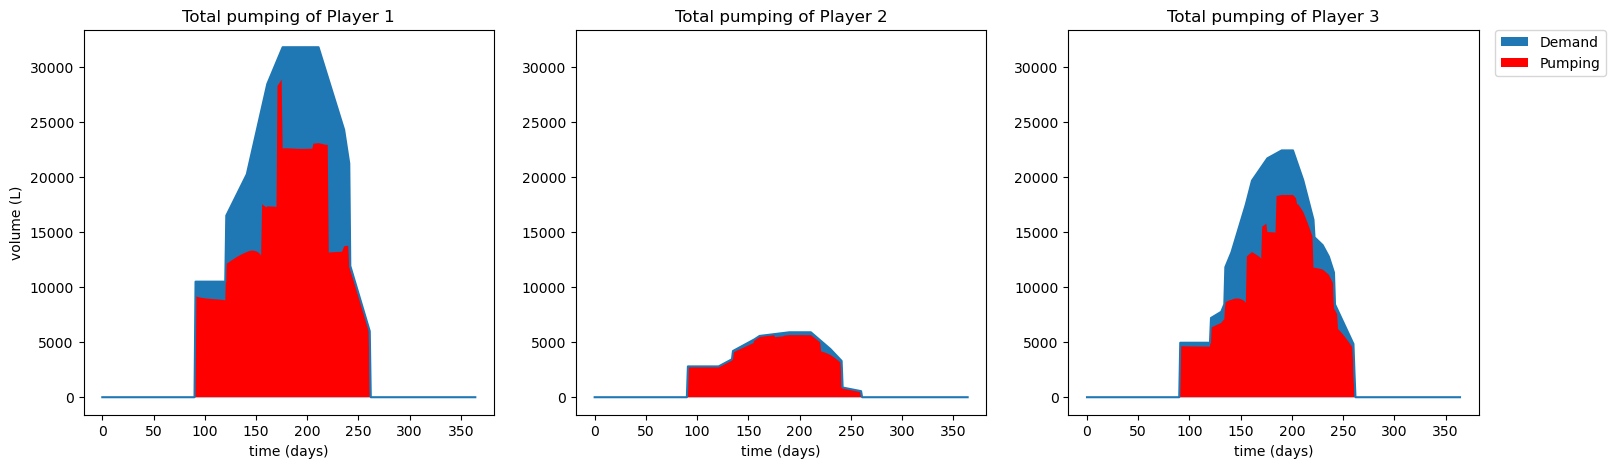

In [115]:
fig = plt.figure(figsize=(15+3,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Total pumping of Player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time (days)")
    if ii == 0:
        ax.set_ylabel("volume (L)")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0))
    ax.fill((water_req+rain)[ii, :, :].sum(axis=0), label='Demand')
    ax.fill(-player_pumping[ii, :] + rain[ii,:,:].sum(axis=0), "r-", label='Pumping')
    # ax.fill(rain[ii,:,:].sum(axis=0), "orange", label='rain')
    # ax.plot((ET_min+rain)[ii, :, :].sum(axis=0), c="cyan", alpha=0.5, label=f'tolerance\n(cost increase: +{tol})')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

### Yield

In [34]:
crop_irrigation = -(sp.block_diag(cost_model.input_to_crop_irrigation_v) @ data['inputs']).reshape(3,4,-1)
yield_proportion = np.where(water_req+rain==0, 0, (1-(crop_irrigation+rain)/(water_req+rain))*cost_model._get_yield_coefficient(0,365))

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_56531/3378870199.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


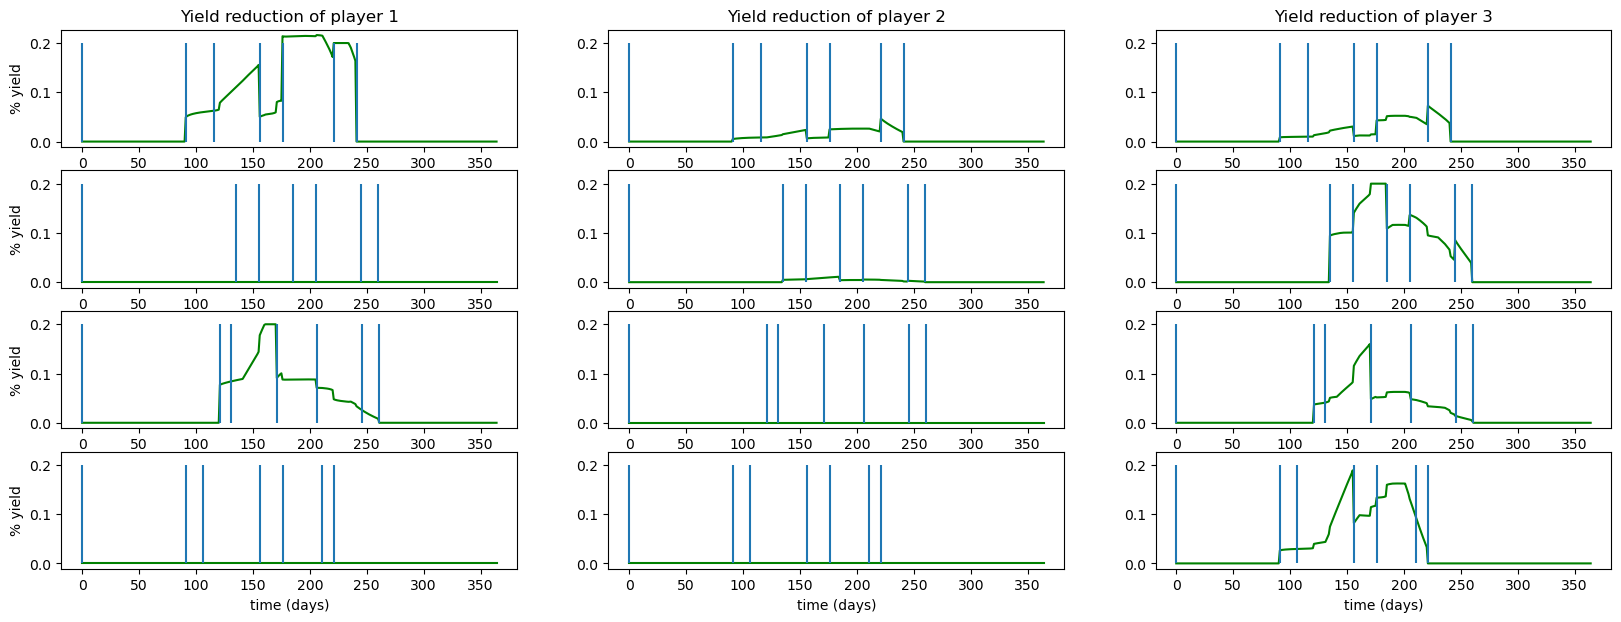

In [109]:
# Plot yield proportion per player an per crops
fig = plt.figure(figsize=(15+5,7))
ax = None
for ii in range(3):
    for jj in range(4):
        ax = fig.add_subplot(4, 3, 3*jj+ii+1, sharey=ax)
        ttl = f"Yield reduction of player {ii+1}"
        if jj == 0:
            ax.set_title(ttl)
        ax.set_xlabel("time (days)")
        if ii == 0:
            ax.set_ylabel("% yield")
        ax.plot(yield_proportion[ii, jj, :], color="green", label='game')
        ax.vlines(cost_model.Ky_stages[jj], 0, 0.2)
#ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

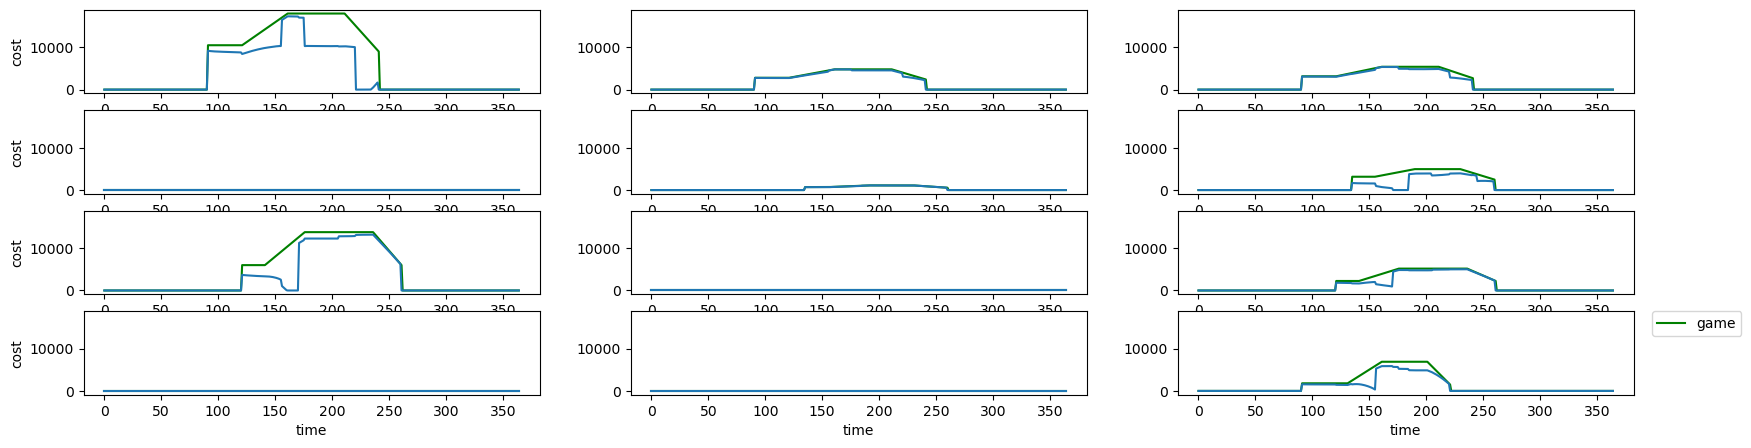

In [43]:
# Plot yield proportion per player an per crops
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    for jj in range(4):
        ax = fig.add_subplot(4, 3, 3*jj+ii+1, sharey=ax)
        ttl = f"Cost for player {ii+1}"
        #ax.set_title(ttl)
        ax.set_xlabel("time")
        if ii == 0:
            ax.set_ylabel("cost")
        ax.plot(water_req[ii, jj, :], color="green", label='game')
        ax.plot(crop_irrigation[ii, jj, :])
        ax.vlines(cost_model.Ky_stages[jj], 0, 0.2)
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_56531/1125730015.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)


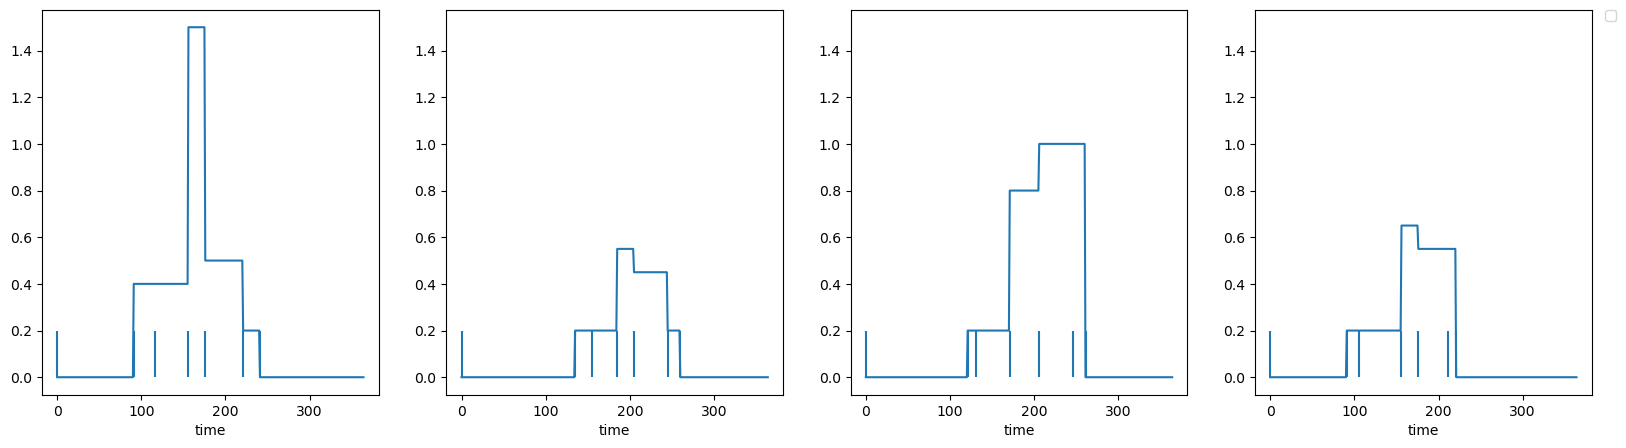

In [46]:
# Plot yield proportion per player an per crops
fig = plt.figure(figsize=(15+5,5))
ax = None
for jj in range(4):
    ax = fig.add_subplot(1, 4, jj+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    #ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(cost_model._get_yield_coefficient(0,365)[jj, :])
    ax.vlines(cost_model.Ky_stages[jj], 0, 0.2)
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [56]:
std = np.array([np.std(yield_proportion[ii, jj, cost_model.Ky_stages[jj][1]:cost_model.Ky_stages[jj][-1]]) for ii in range(3) for jj in range(4)]).reshape(3,4)
mean = np.array([np.mean(yield_proportion[ii, jj, cost_model.Ky_stages[jj][1]:cost_model.Ky_stages[jj][-1]]) for ii in range(3) for jj in range(4)]).reshape(3,4)
mean, std

(array([[0.13614664, 0.        , 0.08415029, 0.        ],
        [0.01806083, 0.00512308, 0.        , 0.        ],
        [0.03055226, 0.11577661, 0.0537225 , 0.09198619]]),
 array([[0.06542593, 0.        , 0.04858392, 0.        ],
        [0.00972282, 0.0023488 , 0.        , 0.        ],
        [0.0187139 , 0.04259571, 0.03483736, 0.05100137]]))

Max 6% deviation

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_56531/2546506825.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


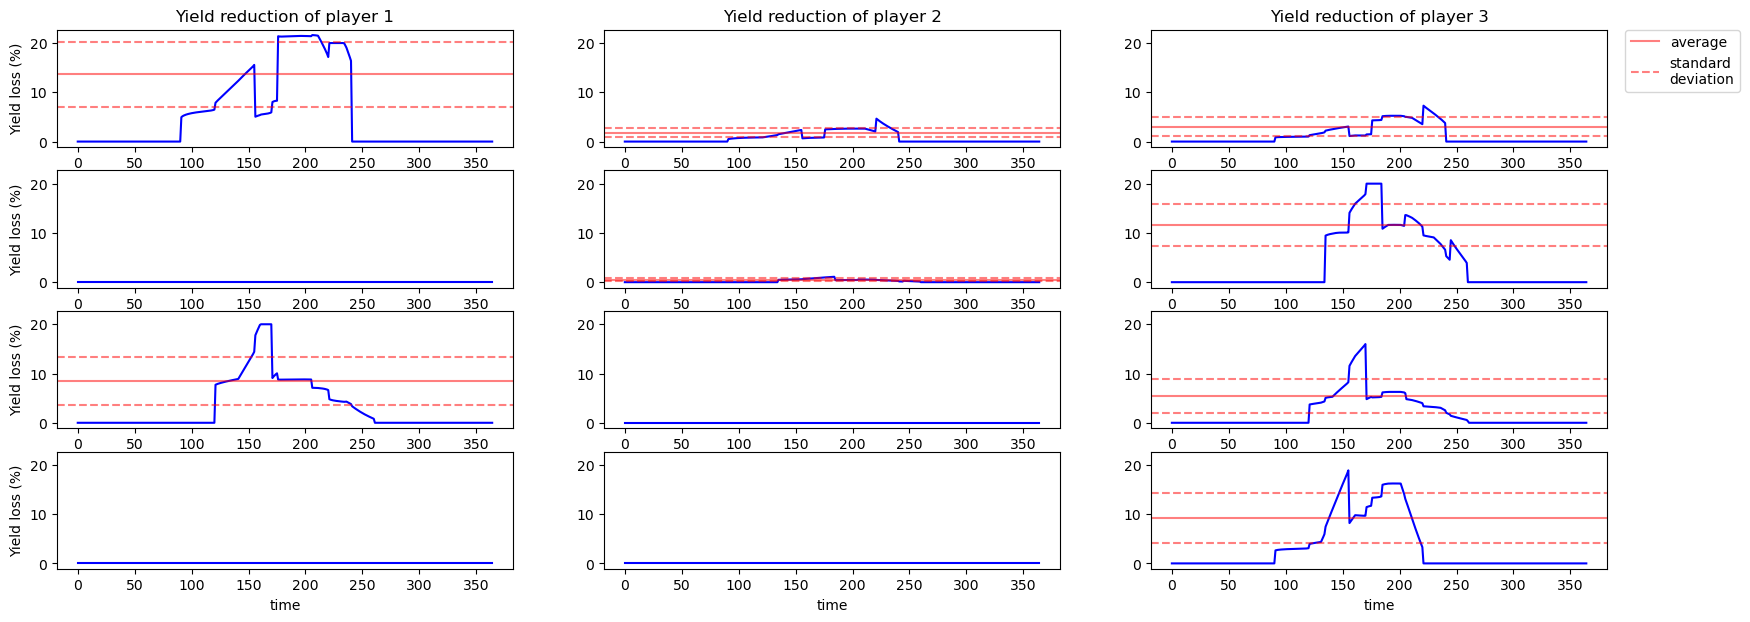

In [111]:
# Plot yield proportion per player an per crops
fig = plt.figure(figsize=(15+5,7))
ax = None
for ii in range(3):
    for jj in range(4):
        ax = fig.add_subplot(4, 3, 3*jj+ii+1, sharey=ax)
        ttl = f"Yield reduction of player {ii+1}"
        if jj == 0:
            ax.set_title(ttl)
        ax.set_xlabel("time")
        if ii == 0:
            ax.set_ylabel("Yield loss (%)")
        ax.plot(100*yield_proportion[ii, jj, :], color="b")
        if mean[ii,jj] != 0:
            ax.axhline(100*mean[ii, jj], alpha= 0.5, c='r', label='average')
            ax.axhline(100*(mean[ii, jj]-std[ii,jj]), c='r', linestyle='--', alpha= 0.5, label='standard\ndeviation')
            ax.axhline(100*(mean[ii, jj]+std[ii,jj]), c='r', linestyle='--', alpha= 0.5)
        if jj == 0 and ii==2:
            ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

In [87]:
(water_req.sum(axis=1).sum(axis=1) + player_pumping.sum(axis=1))/water_req.sum(axis=1).sum(axis=1)

array([0.30783499, 0.04838445, 0.22716849])

In [103]:
(mean*(crop_repartition / crop_repartition.sum(axis=0)).T).sum(axis=1)

array([0.11303715, 0.01547328, 0.07446915])

# Only one crop

In [116]:
parameter_file = "/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250805-172121/model_parameters.json"
crop_repartition = np.array([[1,1,1], [0., 0, 0], [0., 0, 0], [0., 0, 0]])

In [ ]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCostQuadraticDistance(parameter_file, model, crop_repartition)

In [118]:
data = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250805-172121/result_data.npz')

In [201]:
water_req = cost_model._get_water_requirement(0, 365)
rain = cost_model._get_available_water(0, 365)

n_well = int(sum(np.hstack(model.n_well_per_command)))
well_to_agent = np.zeros((model.n_agent, n_well))
indices = np.array(list(zip(model.well_to_agent.tolist(), range(n_well)))).T
well_to_agent[indices[0, :], indices[1, :]] = 1

player_pumping = well_to_agent @ data['q_rates']

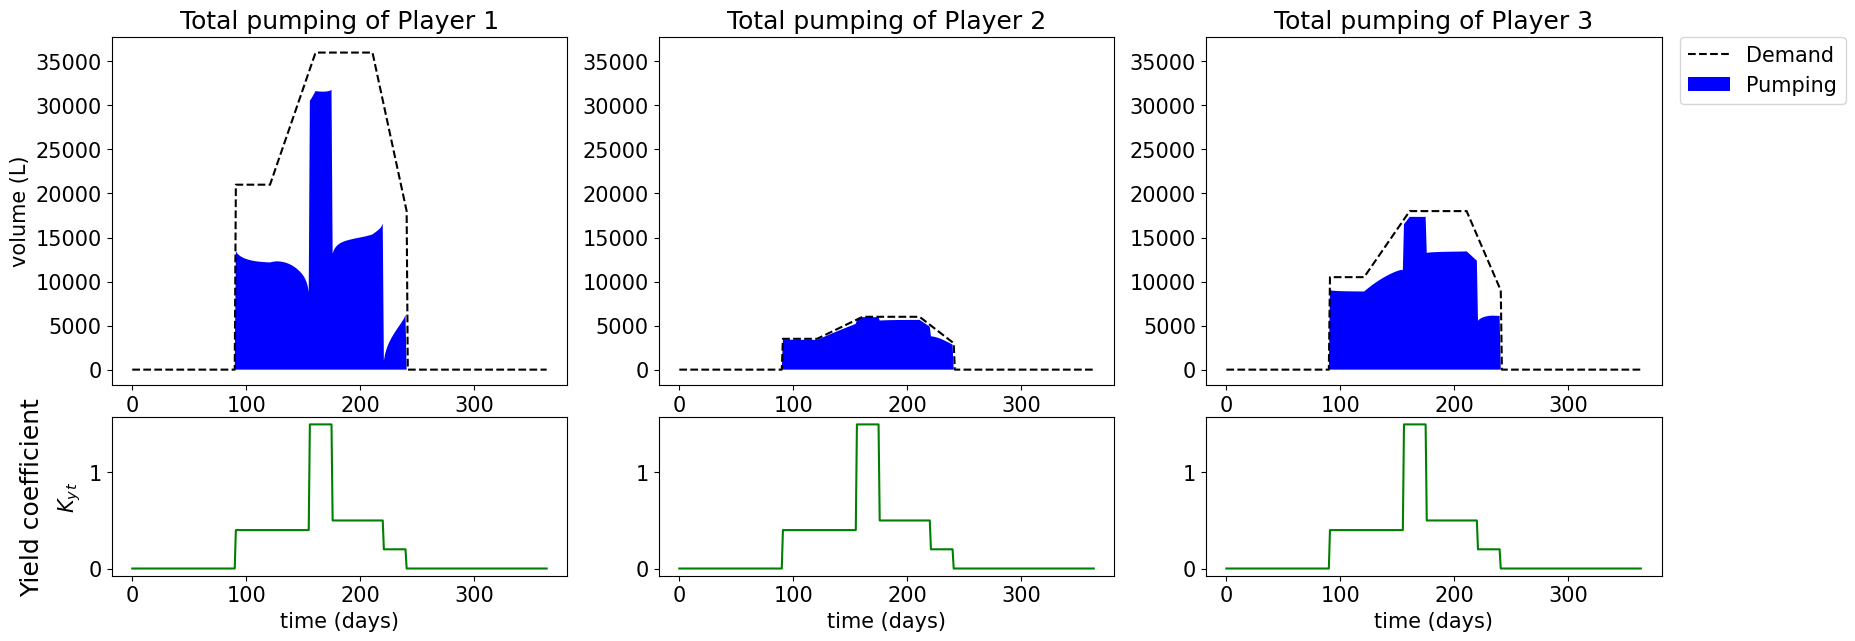

In [207]:
plt.rcParams.update({'font.size': 15})
fig = plt.figure(figsize=(15+5,7))
gs = fig.add_gridspec(3, 3)
ax = None
for ii in range(3):
    ax = fig.add_subplot(gs[:2, ii], sharey=ax)
    ttl = f"Total pumping of Player {ii+1}"
    ax.set_title(ttl)
    #ax.set_xlabel("time (days)")
    if ii == 0:
        ax.set_ylabel("volume (L)")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0), color="black", linestyle="--", label='Demand')
    #ax.fill((water_req+rain)[ii, :, :].sum(axis=0), label='Demand')
    ax.fill(-player_pumping[ii, :] + rain[ii,:,:].sum(axis=0), "b-", label='Pumping')
    # ax.fill(rain[ii,:,:].sum(axis=0), "orange", label='rain')
    # ax.plot((ET_min+rain)[ii, :, :].sum(axis=0), c="cyan", alpha=0.5, label=f'tolerance\n(cost increase: +{tol})')
    #ax.vlines(cost_model.Ky_stages[0], 0, 35000, 'black', alpha=0.5)
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

for ii in range(3):
    ax = fig.add_subplot(gs[2, ii])
    ttl = f"Yield coefficient"
    ax.set_xlabel("time (days)")
    if ii == 0:
        ax.annotate(ttl, xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 5, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
        ax.set_ylabel("${K_y}_{t}$")
    ax.plot(cost_model._get_yield_coefficient(0,365)[0,:], "g")
    #ax.vlines(cost_model.Ky_stages[0], 0, 2, 'black', alpha=0.5)

In [ ]:
def compute_cost(x: np.ndarray, u: np.ndarray, time: int = None) -> np.ndarray:
    """parameter u of shape [n_well, n_crops] contains negative values"""
    u = u.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops))
    ET = cost_model._get_water_requirement(time, 1)[:,:,0]
    Ry = cost_model._get_under_irrigation_weight(time, 1)
    pumping_cost = np.zeros((cost_model.n_agent, 1))
    under_irrigation_cost = np.zeros((cost_model.n_agent, 1))
    for v in range(cost_model.n_agent):
        input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v].T)[1]
        well_indices = np.arange(np.hstack(cost_model.n_well_per_command).sum(), dtype=int)[cost_model.well_to_agent==v]
        pumping_cost[v] = (-cost_model.extraction_cost_v[v] * (cost_model.top_head[input_indices] -\
            x[well_indices]).reshape(-1,1) * u[cost_model.well_to_agent==v,:].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = ET[v, :] + u[cost_model.well_to_agent==v,:].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost[v] = \
            under_irrigation.T @ sp.diags(Ry[v,:].flatten()) @ under_irrigation.T
    return pumping_cost, under_irrigation_cost

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_56531/3427077134.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_56531/3427077134.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


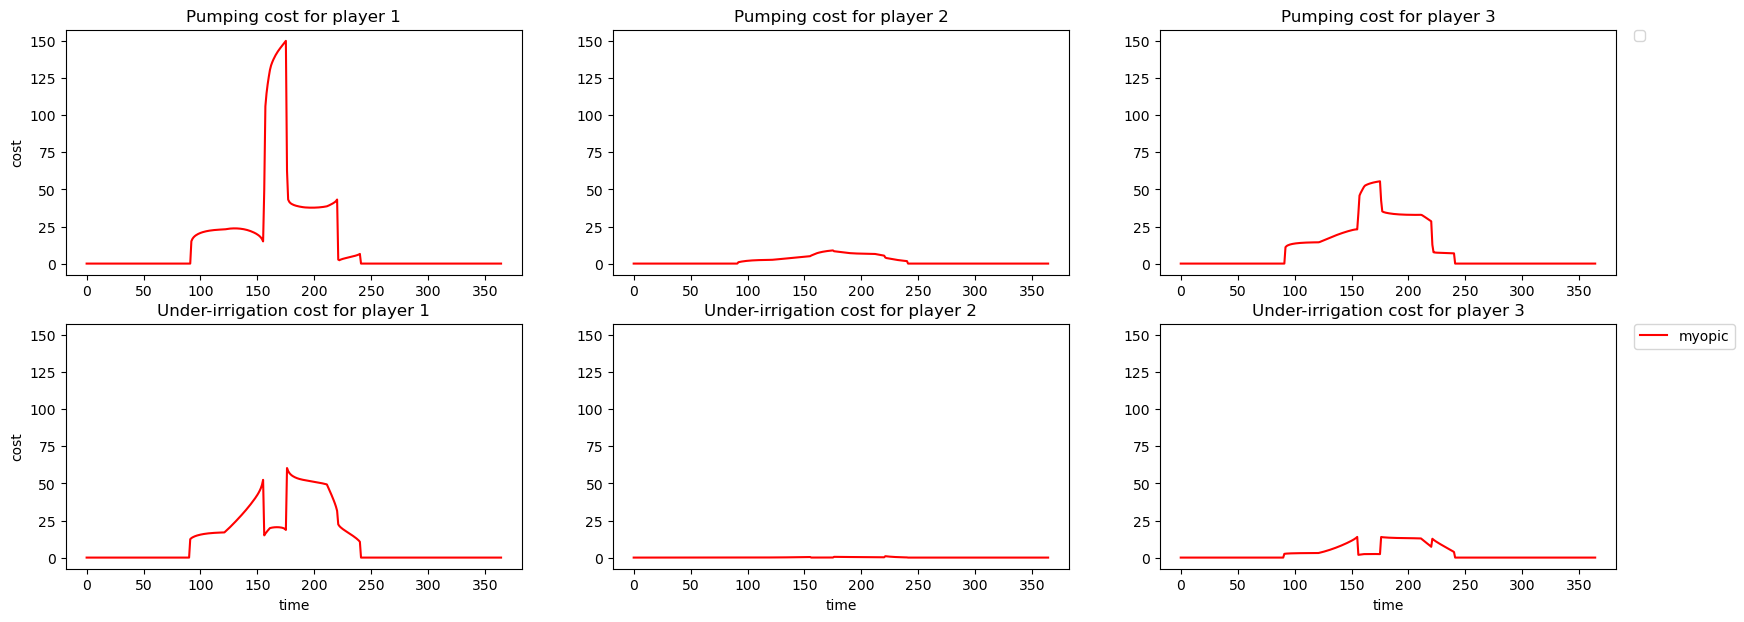

In [136]:
costs = np.hstack([- np.vstack(compute_cost(data['corrected_h_wells'][:,[t]],
                                     model.reorganize_input_per_well(data['inputs'][:,[t]]),
                                     t)) for t in range(365)])
# Plot cost per player
fig = plt.figure(figsize=(15+5,7))
ax = None
for ii in range(3):
    ax = fig.add_subplot(2, 3, ii+1, sharey=ax)
    ttl = f"Pumping cost for player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-costs[ii, :], 'red')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

for ii in range(3):
    ax = fig.add_subplot(2, 3, 3+ii+1, sharey=ax)
    ttl = f"Under-irrigation cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-costs[ii+3, :], 'red', label='myopic')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

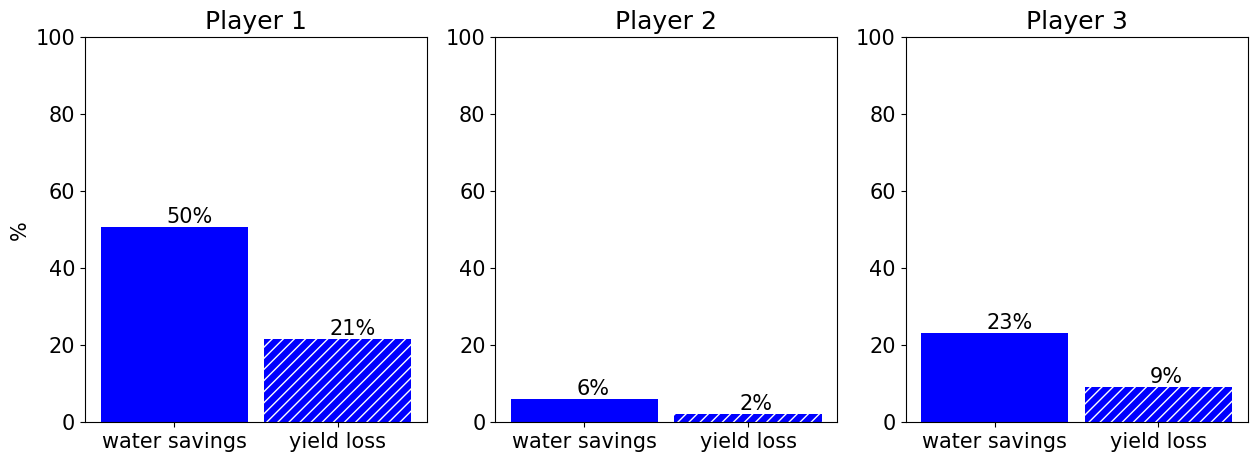

In [208]:
crop_irrigation = -(sp.block_diag(cost_model.input_to_crop_irrigation_v) @ data['inputs']).reshape(3,4,-1)
yield_proportion = np.where(water_req+rain==0, 0, (1-(crop_irrigation+rain)/(water_req+rain))*cost_model._get_yield_coefficient(0,365))

std = np.array([np.std(yield_proportion[ii, jj, cost_model.Ky_stages[jj][1]:cost_model.Ky_stages[jj][-1]]) for ii in range(3) for jj in range(4)]).reshape(3,4)
mean = np.array([np.mean(yield_proportion[ii, jj, cost_model.Ky_stages[jj][1]:cost_model.Ky_stages[jj][-1]]) for ii in range(3) for jj in range(4)]).reshape(3,4)

water_spared = (water_req.sum(axis=1).sum(axis=1) + player_pumping.sum(axis=1))/water_req.sum(axis=1).sum(axis=1)
mean_yield_loss = (mean*(crop_repartition / crop_repartition.sum(axis=0)).T).sum(axis=1)
std_yield_loss = (std*(crop_repartition / crop_repartition.sum(axis=0)).T).sum(axis=1)

fig = plt.figure(figsize=(15,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("%")
    rects = ax.bar([0], [100*water_spared[ii]], width=0.9, color='b')
    rects = ax.bar([1], [100*mean_yield_loss[ii]], width=0.9, color='b', hatch='///')
    #ax.errorbar([1], [100*mean_yield_loss[ii]], [100*std_yield_loss[ii]], capsize = 5, ecolor = 'm', marker = 'none', linestyle = 'none')
    for bar in rects:
        bar._hatch_color = (1.0, 1.0, 1.0, 1.0)
    ax.set_xticks([0,1], ['water savings', 'yield loss'])
    for i, v in enumerate([water_spared[ii], mean_yield_loss[ii]]):
        plt.text(i-0.05, 100*v+1, str(int(100*v))+'%')
    ax.set_ybound([0,100])
#ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

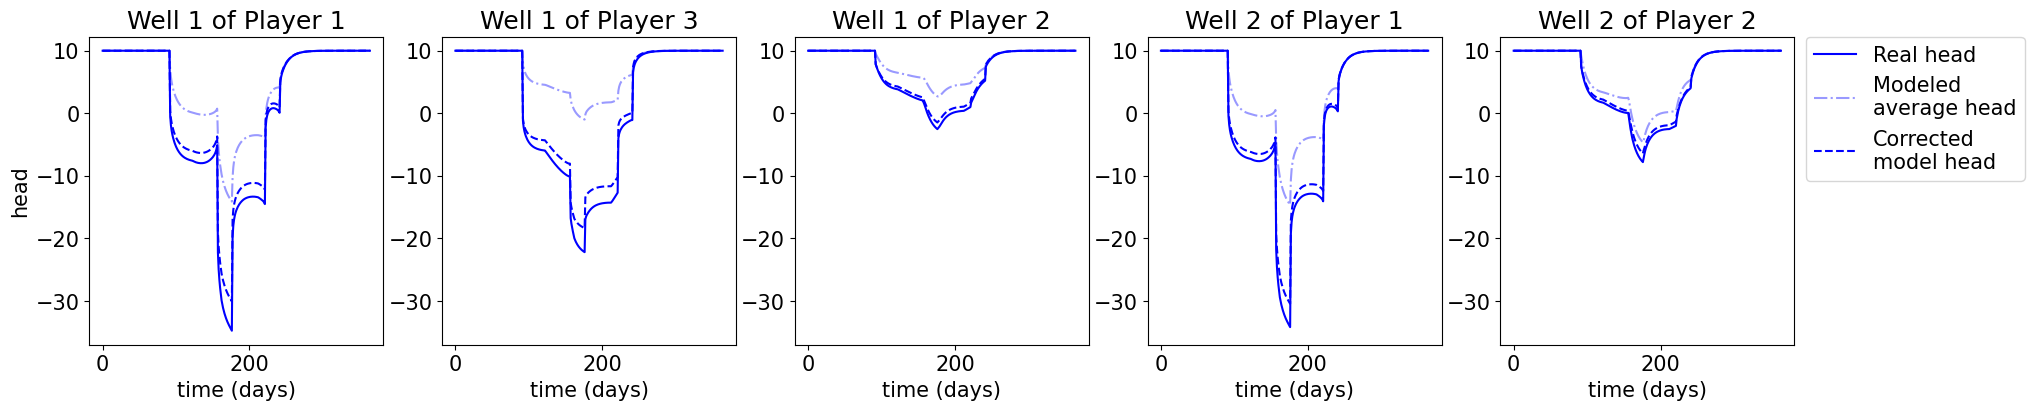

In [211]:
to_player = [0, 2, 1, 0, 1]
n_well_of_player = [1, 1, 1, 2, 2]
# Display heads evolution
fig_h = plt.figure(figsize=(22,4))
ax_h = None
for ii in range(n_well):
    ax_h = fig_h.add_subplot(1, n_well, ii+1, sharey=ax_h)
    ttl = f"Well {n_well_of_player[ii]} of Player {to_player[ii]+1}"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time (days)")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data['h_wells'][ii, :], "b-", label="Real head")
    ax_h.plot(data['avg_h_wells'][ii, :], "b-.", alpha=0.4, label="Modeled\naverage head")
    ax_h.plot(data['corrected_h_wells'][ii, :], "b--", label="Corrected\nmodel head")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)